# Supply Chain Performance Investigation
## Late-2017 Revenue/Order Anomaly and Late-Delivery Risk by Shipping Mode

**Prepared for:** Supply Chain Management  
**Prepared by:** [Insert your name]  
**Dataset:** DataCo Supply Chain — cleaned star-schema exports  
**Purpose:** Investigate two signals identified in the Power BI dashboard and translate evidence into management actions.

---

## Executive summary

This report investigates two dashboard signals: (1) net revenue falls in late 2017 while order counts remain elevated, and (2) recorded late-delivery-risk rates are unusually high for First Class and Second Class shipping.

The first signal is accompanied by a sharp change in item-level structure. Order counts remain around 2,000 per month in October–December 2017, but net revenue per order and item lines per order fall sharply. In November and December, the number of item rows equals the number of distinct orders, with one item row per order. This is a warning that source-data completeness or record structure must be validated before the pattern is interpreted as a change in customer purchasing behaviour.

The second signal is also substantial, but the `late_delivery_risk` flag exactly matches the `delivery_status = "Late delivery"` label in the supplied data. These are not independent confirmations. Shipping-mode differences should be investigated by destination, scheduled delivery duration, and time period before attributing the outcome to the shipping mode itself.

**Management takeaway:** validate the late-2017 data structure first; then investigate shipping-mode differences within comparable operating conditions. The dataset identifies important questions, but it does not yet establish root cause.

## 1. Questions, scope, and metric definitions

### Question A — Why did net revenue fall while order counts stayed high in late 2017?
The analysis decomposes revenue into revenue per order, item lines per order, units per order, and product mix. September–December 2017 is compared with the same months in 2016.

### Question B — Why are recorded late-delivery-risk rates high for First Class and Second Class?
The analysis compares item-level risk rates and delivery-status labels, then examines actual versus scheduled shipping days by shipping mode.

**Metric definitions used**
- **Sales:** sum of `sales`.
- **Net revenue:** sum of `order_item_total`, treated by this project as the after-discount line total.
- **Recorded profit:** sum of `order_profit_per_order`. This is reported as supplied; confirm the source definition and grain before presenting it as audited accounting profit.
- **Orders:** distinct `order_id` from the order/item records.
- **Late-delivery-risk rate:** mean of the item-level `late_delivery_risk` field. The denominator and unit of analysis must be stated whenever reporting this rate.

This is observational analysis. Associations do not prove causality.

## 2. Load data and validate the analysis grain

The notebook uses the cleaned analytical exports. It does not require or load `dim_trash.csv`. Dimension joins use many-to-one validation so accidental row multiplication is caught.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
DATA_DIR = Path("clean_data")

def read_table(name):
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Expected {path}. Run this notebook from the package root.")
    return pd.read_csv(path, encoding="utf-8-sig")

orders = read_table("fact_orders")
items_raw = read_table("fact_order_items")
dates = read_table("dim_date")
customers = read_table("dim_customer")
products = read_table("dim_product")
categories = read_table("dim_category")
shipping_dim = read_table("dim_shipping")
delivery_dim = read_table("dim_delivery_status")
destinations = read_table("dim_destination")

checks = {
    "fact_orders.order_id is unique": orders["order_id"].is_unique,
    "fact_order_items.order_item_id is unique": items_raw["order_item_id"].is_unique,
    "all item order IDs exist in fact_orders": items_raw["order_id"].isin(orders["order_id"]).all(),
}
display(pd.DataFrame({"check": list(checks), "passed": list(checks.values())}))
print(f"Orders: {orders['order_id'].nunique():,}")
print(f"Order-item rows: {len(items_raw):,}")
print(f"Distinct orders in item fact: {items_raw['order_id'].nunique():,}")

,check,passed
0,fact_orders.order_id is unique,True
1,fact_order_items.order_item_id is unique,True
2,all item order IDs exist in fact_orders,True


Orders: 65,752
Order-item rows: 180,519
Distinct orders in item fact: 65,752


In [2]:
order_fields = [c for c in [
    "order_id", "destination_key", "shipping_key", "delivery_status_key", "order_status_key"
] if c in orders.columns]
analysis = items_raw.merge(orders[order_fields], on="order_id", how="left", validate="many_to_one")
analysis = analysis.merge(
    dates[["date_key","full_date","year","month","month_number","month_name","day_name"]],
    left_on="order_date_key", right_on="date_key", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    customers[[c for c in ["customer_key","customer_segment"] if c in customers.columns]].drop_duplicates(),
    on="customer_key", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    products[[c for c in ["product_key","product_name","product_price","product_category_id"] if c in products.columns]].drop_duplicates(),
    on="product_key", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    categories[[c for c in ["category_key","category_name"] if c in categories.columns]].drop_duplicates(),
    on="category_key", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    shipping_dim[["shipping_key","shipping_mode"]].drop_duplicates(),
    on="shipping_key", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    delivery_dim[["delivery_status_key","delivery_status"]].drop_duplicates(),
    on="delivery_status_key", how="left", validate="many_to_one"
)
analysis = analysis.merge(
    destinations[[c for c in ["destination_key","market","order_country","order_region"] if c in destinations.columns]].drop_duplicates(),
    on="destination_key", how="left", validate="many_to_one"
)
analysis["full_date"] = pd.to_datetime(analysis["full_date"], errors="coerce")
analysis["month_start"] = analysis["full_date"].dt.to_period("M").dt.to_timestamp()
assert len(analysis) == len(items_raw), "Join changed row count; investigate before proceeding."
assert analysis["order_item_id"].is_unique, "Item grain was not preserved."
print(f"Analysis table retains {len(analysis):,} item rows.")

Analysis table retains 180,519 item rows.


## 3. Investigation A — Revenue falls while order counts remain elevated

### 3.1 Monthly decomposition

Order count is only one component of revenue. Revenue can decline even when orders rise if average order value, units per order, or product mix changes. The following table separates these indicators.

In [3]:
monthly = analysis.groupby(["year","month_number","month_name","month_start"]).agg(
    sales=("sales","sum"),
    net_revenue=("order_item_total","sum"),
    recorded_profit=("order_profit_per_order","sum"),
    quantity=("order_item_quantity","sum"),
    item_lines=("order_item_id","nunique"),
    orders=("order_id","nunique"),
    customers=("customer_key","nunique")
).reset_index().sort_values("month_start")
monthly["net_revenue_per_order"] = monthly["net_revenue"] / monthly["orders"]
monthly["item_lines_per_order"] = monthly["item_lines"] / monthly["orders"]
monthly["units_per_order"] = monthly["quantity"] / monthly["orders"]
monthly["recorded_profit_margin"] = monthly["recorded_profit"] / monthly["net_revenue"].replace(0, np.nan)

display(monthly[monthly["year"].isin([2016, 2017])][[
    "year","month_name","orders","net_revenue","net_revenue_per_order",
    "item_lines","item_lines_per_order","quantity","units_per_order"
]].round(2))

,year,month_name,orders,net_revenue,net_revenue_per_order,item_lines,item_lines_per_order,quantity,units_per_order
12,2016,January,1772,"940,283.63",530.63,5317,3.00,11597,6.54
13,2016,February,1650,"870,116.75",527.34,4894,2.97,10765,6.52
14,2016,March,1764,"921,487.73",522.39,5210,2.95,11349,6.43
15,2016,April,1706,"900,492.92",527.84,5097,2.99,11208,6.57
16,2016,May,1763,"924,978.22",524.66,5302,3.01,11603,6.58
17,2016,June,1690,"901,448.01",533.40,5054,2.99,11008,6.51
18,2016,July,1758,"939,216.40",534.25,5305,3.02,11652,6.63
19,2016,August,1766,"942,408.94",533.64,5334,3.02,11683,6.62
20,2016,September,1730,"900,371.63",520.45,5160,2.98,11284,6.52
21,2016,October,1776,"941,882.28",530.34,5398,3.04,11936,6.72


In [4]:
late = monthly[monthly["month_number"].between(9,12) & monthly["year"].isin([2016,2017])]
display(late.pivot(index="month_name", columns="year", values=[
    "orders","net_revenue","net_revenue_per_order","item_lines","item_lines_per_order",
    "quantity","units_per_order"
]).round(2))

orders          net_revenue              net_revenue_per_order  \
year           2016     2017        2016         2017                  2016   
month_name                                                                    
December   1,763.00 2,124.00  932,112.89   452,741.53                528.71   
November   1,721.00 2,055.00  941,197.36   563,393.47                546.89   
October    1,776.00 2,101.00  941,882.28   966,081.41                530.34   
September  1,730.00 1,723.00  900,371.63 1,027,111.73                520.45   

                  item_lines          item_lines_per_order       quantity  \
year         2017       2016     2017                 2016 2017      2016   
month_name                                                                  
December   213.16   5,269.00 2,124.00                 2.99 1.00 11,774.00   
November   274.16   5,210.00 2,055.00                 3.03 1.00 11,493.00   
October    459.82   5,398.00 2,255.00                 3.04 1.07 11,936.00   
September  596.12   5,160.00 5,189.00                 2.98 3.01 11,284.00   

                     units_per_order       
year            2017            2016 2017  
month_name                                 
December    2,124.00            6.68 1.00  
November    2,055.00            6.68 1.00  
October     2,490.00            6.72 1.19  
September  10,502.00            6.52 6.10

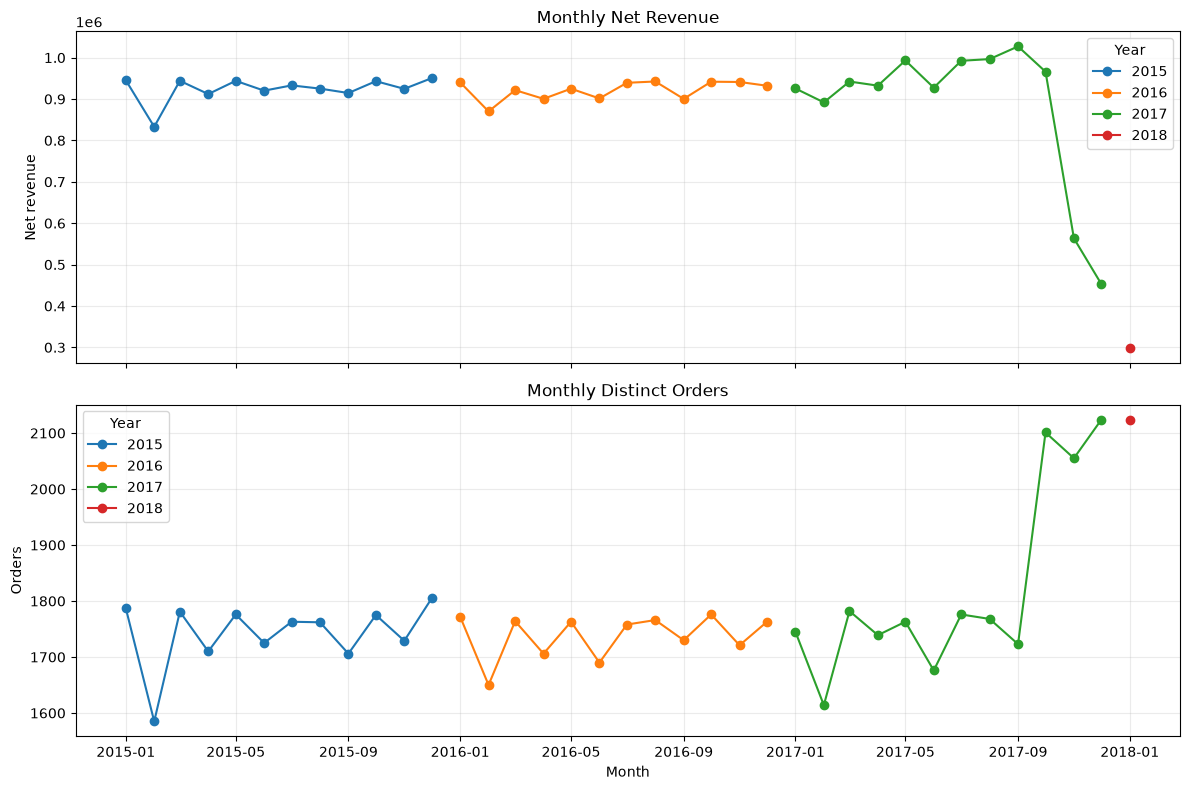

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for year, group in monthly.groupby("year"):
    axes[0].plot(group["month_start"], group["net_revenue"], marker="o", label=str(year))
    axes[1].plot(group["month_start"], group["orders"], marker="o", label=str(year))
axes[0].set_title("Monthly Net Revenue")
axes[0].set_ylabel("Net revenue")
axes[1].set_title("Monthly Distinct Orders")
axes[1].set_ylabel("Orders")
axes[1].set_xlabel("Month")
for ax in axes:
    ax.grid(True, alpha=.25)
    ax.legend(title="Year")
plt.tight_layout()
plt.show()

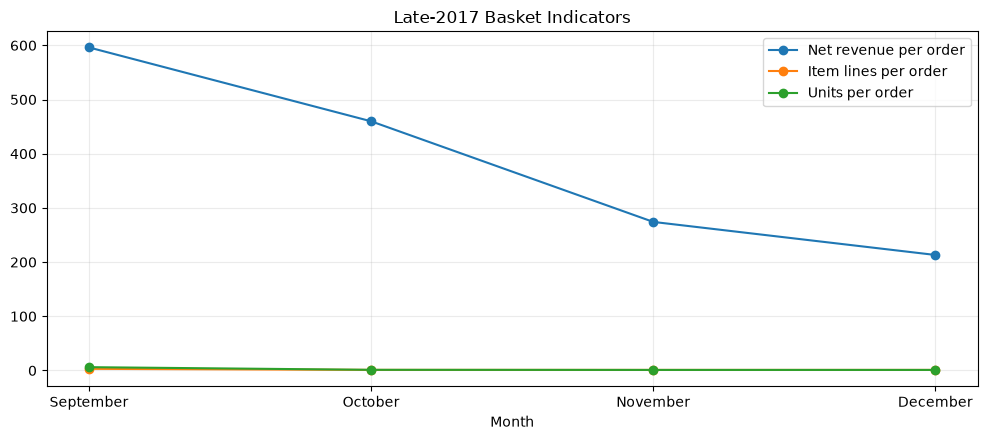

In [6]:
late17 = monthly[(monthly["year"] == 2017) & monthly["month_number"].between(9,12)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(late17["month_name"], late17["net_revenue_per_order"], marker="o", label="Net revenue per order")
ax.plot(late17["month_name"], late17["item_lines_per_order"], marker="o", label="Item lines per order")
ax.plot(late17["month_name"], late17["units_per_order"], marker="o", label="Units per order")
ax.set_title("Late-2017 Basket Indicators")
ax.set_xlabel("Month")
ax.grid(True, alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 What the current evidence supports

The supplied clean exports show a sharp structural change beginning in October 2017:
- Order counts remain around 2,000 per month in October–December.
- Net revenue per order falls substantially.
- Item lines per order fall sharply from earlier-year levels.
- In November and December, item-row count equals distinct order count, meaning one item row per order in the exported item fact; recorded quantity also equals order count.

This is not enough to claim that customers intentionally began buying smaller baskets. The coincidence of the revenue decline and the change in item-line structure makes source-data completeness and grain the first hypothesis to test.

### 3.3 Follow-up tests before a business conclusion

1. Reconcile raw versus cleaned row counts and order-item IDs for October–December 2017.
2. Check source extract completeness, missing product rows, and whether quantity fields changed meaning.
3. Once the row structure is validated, decompose revenue by product mix, unit price, customer segment, and market.
4. Compare late 2017 with the same months in 2016.
5. Only then decide whether this is a genuine commercial change or a data artifact.

**Provisional conclusion:** the anomaly is visible in the supplied exports, but a business explanation is premature until the late-2017 item-level structure is validated.

## 4. Investigation B — Late-delivery risk by shipping mode

### 4.1 Mode comparison

The table compares item-level risk rate, the share labelled `Late delivery`, distinct order counts, and average actual versus scheduled shipping duration. These rates describe the supplied records and should not be interpreted as causal effects.

In [7]:
shipping_summary = analysis.groupby("shipping_mode", dropna=False).agg(
    item_rows=("order_item_id","nunique"),
    orders=("order_id","nunique"),
    late_risk_rate=("late_delivery_risk","mean"),
    late_status_rate=("delivery_status", lambda s: (s == "Late delivery").mean()),
    avg_actual_days=("days_for_shipping_(real)","mean"),
    avg_scheduled_days=("days_for_shipment_(scheduled)","mean")
).reset_index()
shipping_summary["avg_variance_days"] = shipping_summary["avg_actual_days"] - shipping_summary["avg_scheduled_days"]
display(shipping_summary.sort_values("late_risk_rate", ascending=False).round(3))

risk = pd.to_numeric(analysis["late_delivery_risk"], errors="coerce")
late_label = (analysis["delivery_status"] == "Late delivery").astype(float)
print("Risk flag exactly matches Late delivery status:",
      f"{(risk == late_label).mean():.1%}")

,shipping_mode,item_rows,orders,late_risk_rate,late_status_rate,avg_actual_days,avg_scheduled_days,avg_variance_days
0,First Class,27814,10079,0.95,0.95,2.00,1.00,1.00
2,Second Class,35216,12778,0.77,0.77,3.99,2.00,1.99
1,Same Day,9737,3571,0.46,0.46,0.48,0.00,0.48
3,Standard Class,107752,39324,0.38,0.38,4.00,4.00,-0.00


Risk flag exactly matches Late delivery status: 100.0%


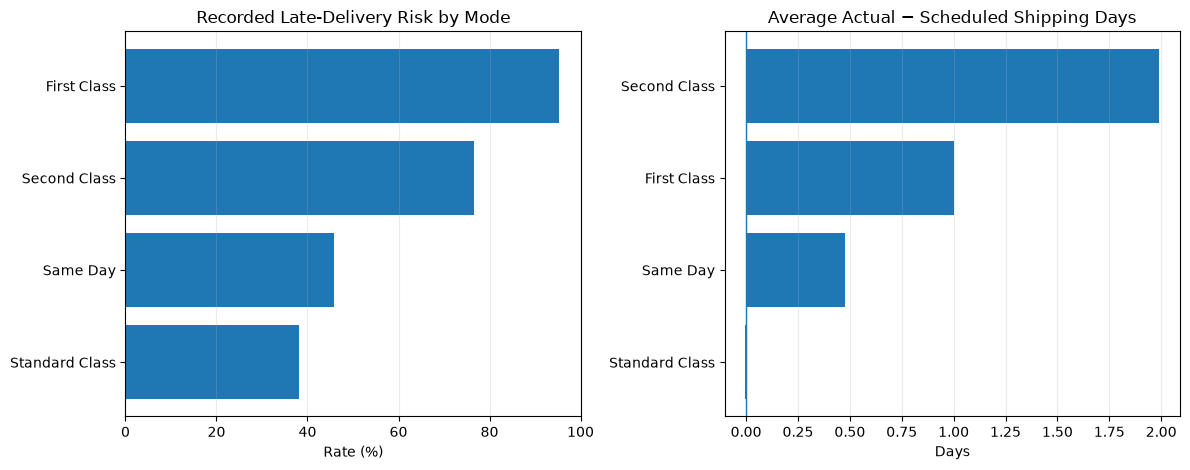

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
s = shipping_summary.sort_values("late_risk_rate")
axes[0].barh(s["shipping_mode"].astype(str), s["late_risk_rate"] * 100)
axes[0].set_title("Recorded Late-Delivery Risk by Mode")
axes[0].set_xlabel("Rate (%)")
axes[0].grid(axis="x", alpha=.25)

s = shipping_summary.sort_values("avg_variance_days")
axes[1].barh(s["shipping_mode"].astype(str), s["avg_variance_days"])
axes[1].axvline(0, linewidth=1)
axes[1].set_title("Average Actual − Scheduled Shipping Days")
axes[1].set_xlabel("Days")
axes[1].grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

### 4.2 Interpretation and limitations

First Class and Second Class have the highest recorded late-delivery-risk rates in the supplied data. However, the risk flag exactly matches the `Late delivery` status label, so the two fields are not independent evidence.

The shipping mode itself may not be the cause. Modes can differ in destination, promised delivery duration, order profile, or time period. The next step is to compare similar shipments rather than ranking modes on the raw rate alone.

### 4.3 Follow-up tests

1. Compare modes within the same market/destination and similar scheduled delivery windows.
2. Compare actual shipping days against scheduled days, not just the binary risk flag.
3. Define the eligible-shipment denominator and decide how cancelled/pending orders are treated.
4. Check whether the gap persists over time or is concentrated in particular periods.
5. Confirm the source definition of `late_delivery_risk` before describing it as an independently observed delivery KPI.

**Provisional conclusion:** the difference is a strong investigation lead, but the current data does not establish that shipping mode causes late delivery.

## 5. Recommendations for management

| Priority | Recommended action | Rationale | Evidence required |
|---|---|---|---|
| 1 | Investigate late-2017 data completeness and item-level structure | Revenue/order divergence coincides with a sharp decline in item lines per order | Raw-to-clean reconciliation, order-item coverage, source extract checks |
| 2 | Decompose late-2017 revenue after data validation | Distinguishes commercial drivers from data issues | Stable row grain and comparable monthly metric definitions |
| 3 | Compare shipping modes within comparable destinations and delivery commitments | Reduces mix-related confounding | Within-market and within-scheduled-window comparisons |
| 4 | Validate late-delivery risk definitions and denominator | Risk flag matches the delivery-status label | Source documentation and eligible-shipment rules |
| 5 | Establish ongoing monitoring after investigation | Makes outcomes measurable | Agreed KPI definitions, owner, and review cadence |

These are diagnostic recommendations, not instructions to change shipping policies immediately. Intervention should follow validated evidence.

## 6. Conclusion

Two dashboard signals deserve follow-up. First, late-2017 net revenue fell while order counts remained elevated. The decomposition shows that item lines and units per order also fell sharply, and the item-level structure changes abruptly in the final months. This makes data completeness and grain validation the immediate priority before attributing the decline to customer behaviour.

Second, recorded late-delivery risk differs substantially by shipping mode. Since the risk flag matches the delivery-status label exactly, the two fields do not independently corroborate the result. Destination, scheduled delivery duration, and time period should be accounted for before recommending operational changes.

The recommended sequence is to validate the late-2017 data, quantify commercial drivers on a trusted base, and then compare shipping-mode performance under comparable operating conditions.

## Appendix — Reproducibility

- Run from the package root so `clean_data/` is available.
- Dependencies: `pandas`, `numpy`, `matplotlib`, `ipython`.
- The notebook does not load `dim_trash.csv`.
- Net revenue is defined as `sum(order_item_total)` in line with the current project model.
- Recorded profit is `sum(order_profit_per_order)` and requires confirmation of its source definition/grain before external financial claims.
- Late-delivery risk is an item-level rate; state its denominator whenever presenting it.
- The available dataset does not independently establish root cause or provide external operational records.